les bibliotheques sont importees avec succes.
    Temperature  Repetition  Graines_testes  Graines_germees
0            10           1              25               10
1            10           2              25               11
2            10           3              25                9
3            10           4              25               10
4            15           1              25               16
5            15           2              25               17
6            15           3              25               15
7            15           4              25               16
8            20           1              25               21
9            20           2              25               22
10           20           3              25               20
11           20           4              25               21
12           25           1              25               23
13           25           2              25               24
14           25           3            

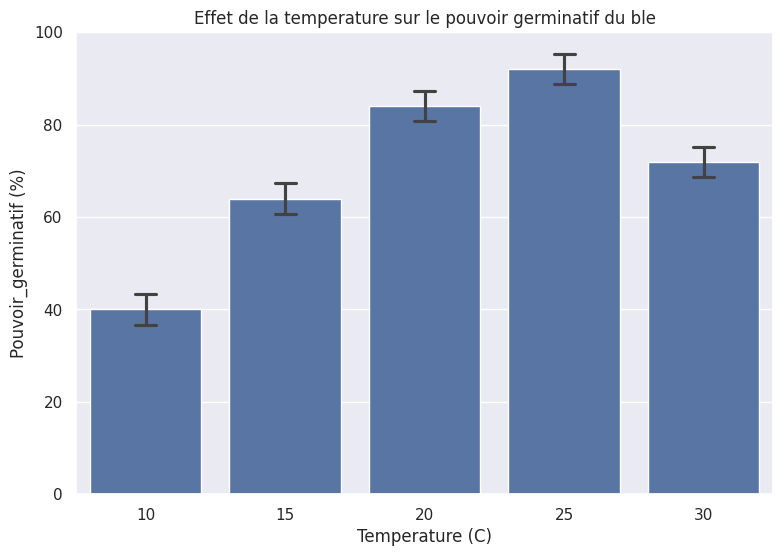

les resultats sont eneregistres


In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
print ("les bibliotheques sont importees avec succes.")
Donnees= {
    "Temperature":[10,10,10,10,
                   15,15,15,15,
                   20,20,20,20,
                   25,25,25,25,
                   30,30,30,30],
    "Repetition": [1, 2, 3, 4]* 5,
    "Graines_testes": [25] * 20,
    "Graines_germees": [
        10, 11, 9, 10,
        16, 17, 15, 16,
        21, 22, 20, 21,
        23, 24, 22, 23,
        18, 19, 17, 18,
    ]
}
df= pd.DataFrame(Donnees)
print(df)
df["Pouvoir_germinatif"]= (
    df["Graines_germees"]
    / df["Graines_testes"]
) * 100
print(df)
resultats = df.groupby("Temperature")[
    "Pouvoir_germinatif"
].agg(["mean","std"]).reset_index()
resultats.columns = [
    "Temperature",
    "Moyenne_PG",
    "Ecar_type_PG",
]
print(resultats)
sns.set_theme(style="darkgrid")
plt.figure(figsize=(9, 6))
sns.barplot(
    data=df,
    x="Temperature",
    y="Pouvoir_germinatif",
    errorbar="sd",
    capsize=0.15
)
plt.title(
    "Effet de la temperature sur le pouvoir germinatif du ble"
)
plt.xlabel("Temperature (C)")
plt.ylabel("Pouvoir_germinatif (%)")
plt.ylim(0, 100)
plt.savefig(
    "graphic_germination_ble.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
df.to_csv(
    "resultats_germination_ble.csv",
    index=False
)
print("les resultats sont eneregistres")
